# 1 · The independence assumption

The navigation system under the classical independence assumption, its minimal cut sets, and
what redundancy is claimed to buy. See [Lesson 1](../docs/lessons/01-the-independence-assumption.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from cyberccf import plotting
from cyberccf.independence_baseline import MISSION_HOURS, navigation_model, unreliability

plotting.use_style()

In [2]:
from cyberccf.independence_baseline import describe, minimal_cut_sets

single = navigation_model()
dual = navigation_model(mission_computers=2)
print(describe(single.structure))
print(f"P(loss), one computer:  {unreliability(single, MISSION_HOURS):.4e}")
print(f"P(loss), two computers: {unreliability(dual, MISSION_HOURS):.4e}")
q = single.probabilities(MISSION_HOURS)
for cut in sorted(minimal_cut_sets(single), key=lambda c: -np.prod([q[e] for e in c])):
    print(f"{' + '.join(sorted(cut)):32s} {np.prod([q[e] for e in cut]):.3e}")

series(parallel(series(egi_1, power_bus_1), series(egi_2, power_bus_2)), parallel(bus_ch_a, bus_ch_b), mission_computer, parallel(power_bus_1, power_bus_2))
P(loss), one computer:  5.0471e-04
P(loss), two computers: 5.0892e-06
mission_computer                 4.999e-04
egi_1 + egi_2                    3.992e-06
egi_1 + power_bus_2              3.996e-07
egi_2 + power_bus_1              3.996e-07
power_bus_1 + power_bus_2        3.999e-08
bus_ch_a + bus_ch_b              9.999e-09


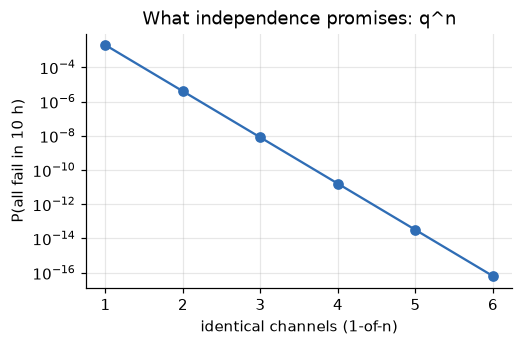

In [3]:
q_egi = q["egi_1"]
ns = np.arange(1, 7)
fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogy(ns, q_egi**ns, "o-", color=plotting.INDEPENDENT_COLOR)
ax.set_xlabel("identical channels (1-of-n)")
ax.set_ylabel("P(all fail in 10 h)")
ax.set_title("What independence promises: q^n");